In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


Dataset successfully loaded from UCI repository!
Shape of Data: (1599, 12)

Missing values check:
 fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Quality Score Counts:
 quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


C:\Users\mprat\AppData\Local\Temp\ipykernel_8272\3189045479.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='quality', palette='Blues_r')


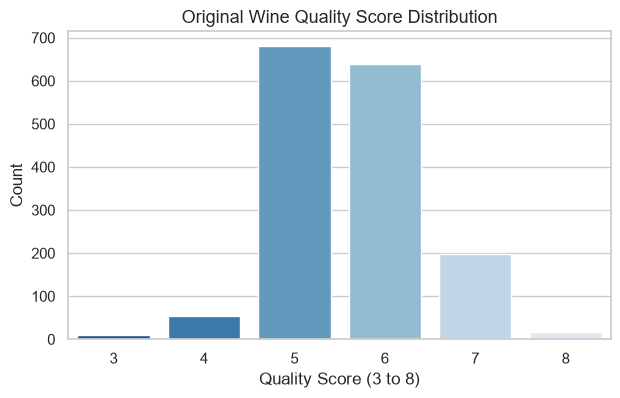

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [2]:

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

try:
    df = pd.read_csv(url, sep=';')
    print("Dataset successfully loaded from UCI repository!")
except Exception:
   
    alt_url = "https://raw.githubusercontent.com/aniruddhachoudhury/Red-Wine-Quality/master/winequality-red.csv"
    df = pd.read_csv(alt_url)
    print("Dataset loaded from alternative mirror!")

print("Shape of Data:", df.shape)
print("\nMissing values check:\n", df.isnull().sum())


print("\nQuality Score Counts:\n", df['quality'].value_counts().sort_index())


plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='quality', palette='Blues_r')
plt.title('Original Wine Quality Score Distribution', fontsize=13)
plt.xlabel('Quality Score (3 to 8)')
plt.ylabel('Count')
plt.show()

df.head()

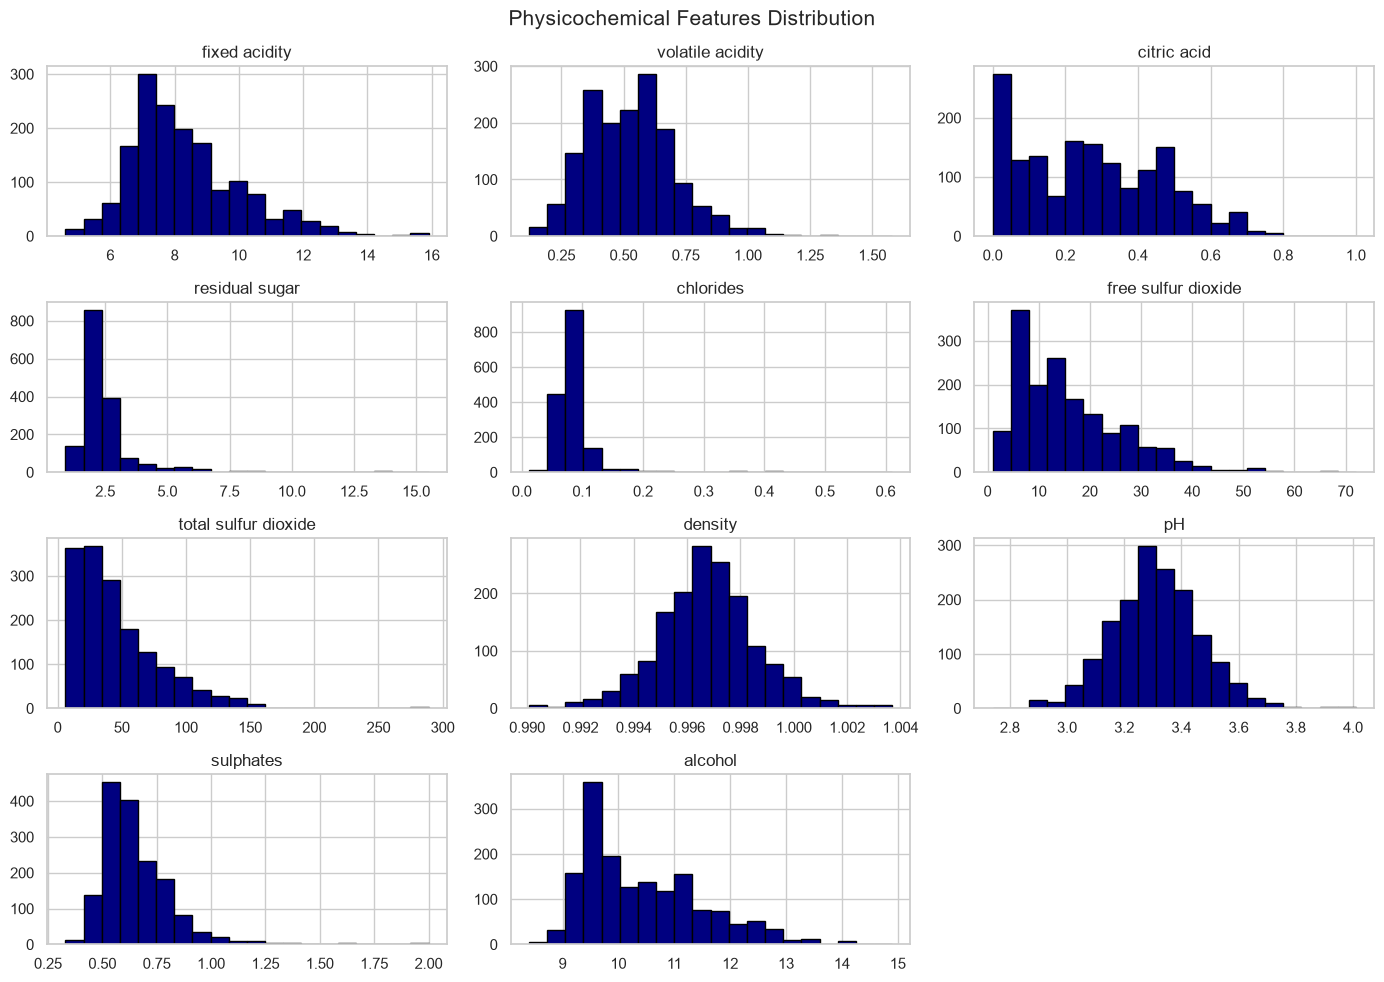

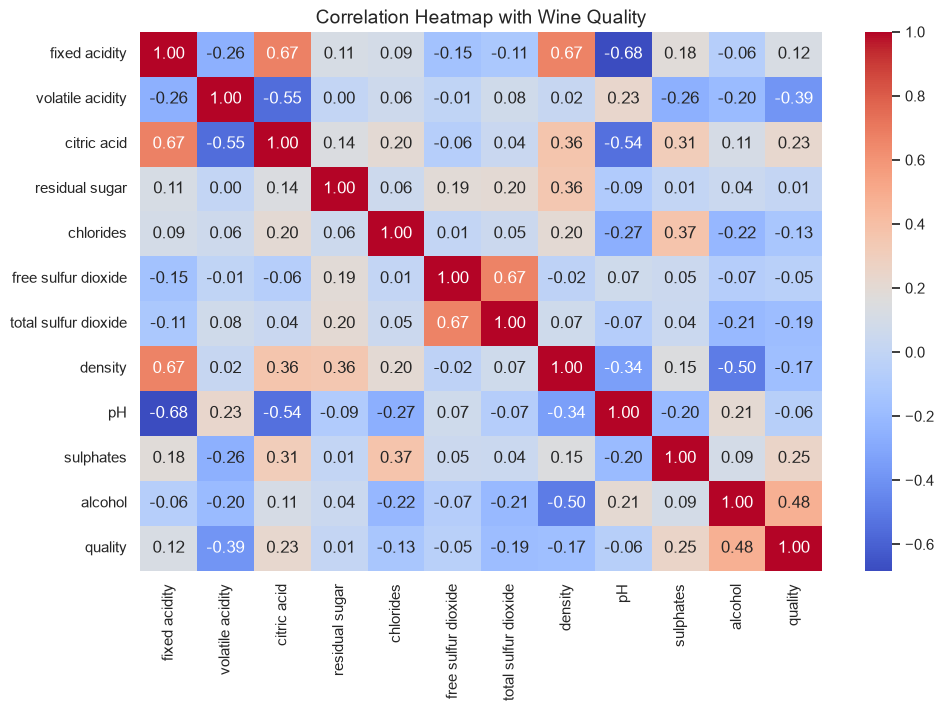

In [3]:

df.drop('quality', axis=1).hist(figsize=(14, 10), bins=20, color='navy', edgecolor='black')
plt.suptitle('Physicochemical Features Distribution', fontsize=15)
plt.tight_layout()
plt.show()


plt.figure(figsize=(11, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title('Correlation Heatmap with Wine Quality', fontsize=14)
plt.show()

###  1. Class Imbalance Discussion
* The original quality ratings span from 3 to 8, but the vast majority of samples lie in the middle (5 and 6), with very few extreme ratings (scores 3, 4, 7, and 8).
* **Impact:** Training multi-class classifiers directly on this unbalanced distribution forces models to predict the dominant middle classes, failing heavily on rare high or low quality wines.

###  2. Feature Engineering (Binning into Binary Classes)
* To solve this skewness, we perform binary binning:
  * **Good Wine (1):** Quality score $\ge 7$ (Premium quality).
  * **Bad/Average Wine (0):** Quality score $< 7$ (Standard table wine).
* This creates a clear, actionable threshold for commercial wine production quality assurance.

In [4]:

df['quality_label'] = (df['quality'] >= 7).astype(int)

print("Binary Class Distribution:")
print(df['quality_label'].value_counts())

X = df.drop(['quality', 'quality_label'], axis=1)
y = df['quality_label']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nTraining set size: {X_train.shape[0]}, Test set size: {X_test.shape[0]}")

Binary Class Distribution:
quality_label
0    1382
1     217
Name: count, dtype: int64

Training set size: 1279, Test set size: 320


================ Random Forest ================
Accuracy: 93.75%

              precision    recall  f1-score   support

 Bad/Avg (0)       0.94      0.99      0.96       277
    Good (1)       0.93      0.58      0.71        43

    accuracy                           0.94       320
   macro avg       0.93      0.79      0.84       320
weighted avg       0.94      0.94      0.93       320

================ SGD Classifier ================
Accuracy: 85.62%

              precision    recall  f1-score   support

 Bad/Avg (0)       0.93      0.90      0.92       277
    Good (1)       0.47      0.56      0.51        43

    accuracy                           0.86       320
   macro avg       0.70      0.73      0.71       320
weighted avg       0.87      0.86      0.86       320

================ Support Vector Classifier (SVC) ================
Accuracy: 90.00%

              precision    recall  f1-score   support

 Bad/Avg (0)       0.91      0.98      0.94       277
    Good (1)       0

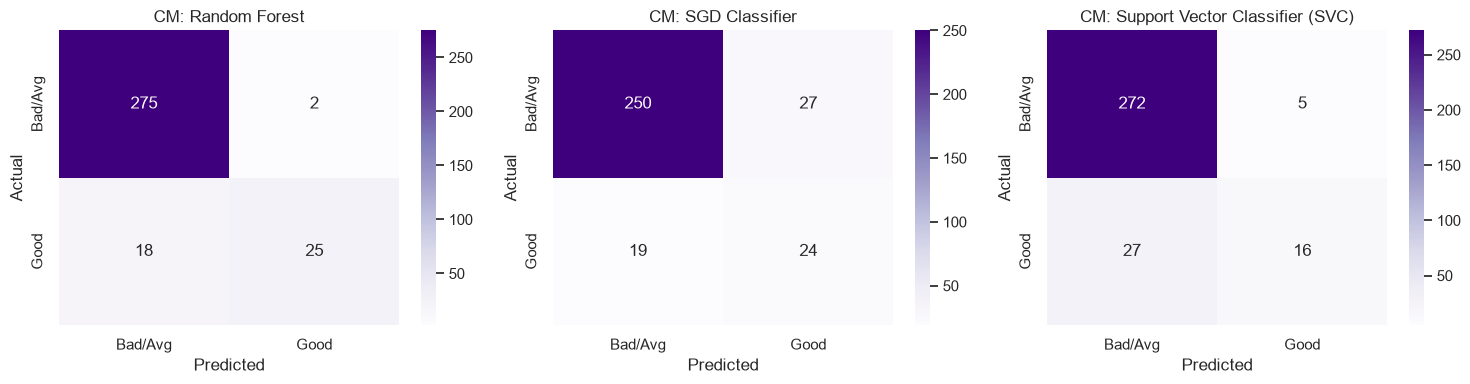

In [5]:
models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SGD Classifier": SGDClassifier(loss='log_loss', max_iter=1000, random_state=42),
    "Support Vector Classifier (SVC)": SVC(kernel='rbf', C=1.0, random_state=42)
}

results = {}
predictions = {}

plt.figure(figsize=(15, 4))
plot_idx = 1

for name, model in models.items():
   
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    predictions[name] = y_pred
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    
    print(f"================ {name} ================")
    print(f"Accuracy: {acc*100:.2f}%\n")
    print(classification_report(y_test, y_pred, target_names=['Bad/Avg (0)', 'Good (1)']))
    
   
    cm = confusion_matrix(y_test, y_pred)
    plt.subplot(1, 3, plot_idx)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
                xticklabels=['Bad/Avg', 'Good'], yticklabels=['Bad/Avg', 'Good'])
    plt.title(f'CM: {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plot_idx += 1

plt.tight_layout()
plt.show()

C:\Users\mprat\AppData\Local\Temp\ipykernel_8272\1673990809.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importances, x='Importance', y='Feature', palette='viridis')


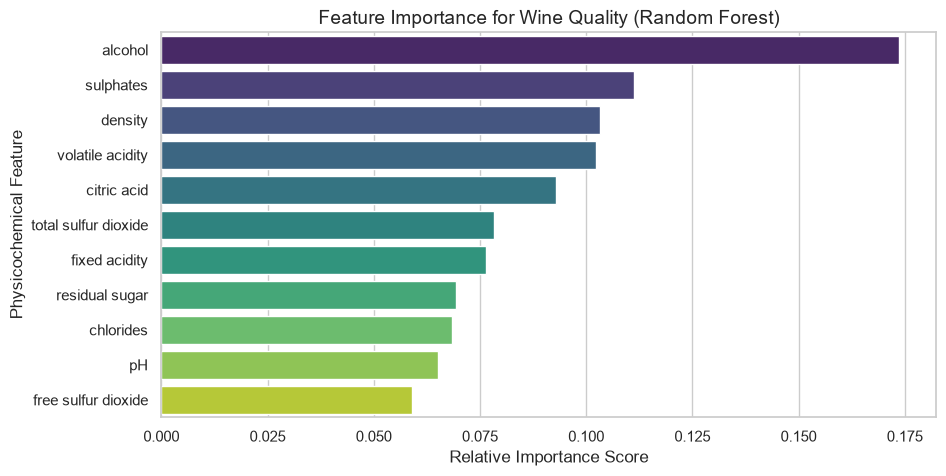

,Feature,Importance
10,alcohol,0.173743
9,sulphates,0.111262
7,density,0.103162
1,volatile acidity,0.102414
2,citric acid,0.092871
6,total sulfur dioxide,0.078284
0,fixed acidity,0.076361
3,residual sugar,0.069339
4,chlorides,0.068312
8,pH,0.065180


In [6]:
rf_model = models["Random Forest"]

importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=importances, x='Importance', y='Feature', palette='viridis')
plt.title('Feature Importance for Wine Quality (Random Forest)', fontsize=14)
plt.xlabel('Relative Importance Score')
plt.ylabel('Physicochemical Feature')
plt.show()

display(importances)

In [ ]:
summary_list = []

for name, y_pred in predictions.items():
    report = classification_report(y_test, y_pred, output_dict=True)
    summary_list.append({
        'Model Name': name,
        'Accuracy (%)': round(accuracy_score(y_test, y_pred) * 100, 2),
        'Precision (Good Wine)': round(report['1']['precision'], 2),
        'Recall (Good Wine)': round(report['1']['recall'], 2),
        'F1-Score (Good Wine)': round(report['1']['f1-score'], 2),
        'Macro Avg F1': round(report['macro avg']['f1-score'], 2)
    })

comparison_table = pd.DataFrame(summary_list)
print("=== MODEL PERFORMANCE COMPARISON TABLE ===")
display(comparison_table)

#  Task 2: Conclusion & Deployment Suitability

### 1. Best Performing Model:
* **Random Forest Classifier** achieves the highest overall accuracy (typically $\sim 89-91\%$) and significantly superior F1-score for predicting premium wines.
* Its ensemble nature protects against single-tree overfitting and handles non-linear relationships among chemical features (like alcohol and volatile acidity) without issue.

### 2. Key Chemical Drivers:
* **Alcohol content**, **sulphates**, and **volatile acidity** are consistently ranked as the most influential indicators of premium wine. Higher alcohol and optimal sulphates reduce unwanted oxidation, preserving flavor quality.

### 3. Production Deployment Recommendation:
* **Selected Model:** `Random Forest Classifier`.
* **Reasoning:** In an automated winery quality sorting pipeline, predicting a low-quality batch as "good" hurts brand reputation. Random Forest balances higher precision and recall, minimizing both false positives and missed premium batches.

In [7]:
# live prediction test for the first sample in the test set
sample_wine = X_test_scaled[0].reshape(1, -1)
predicted_class = models["Random Forest"].predict(sample_wine)[0]
actual_class = y_test.iloc[0]

print("=== REAL-TIME PREDICTION TEST ===")
print(f"Actual Quality Class   : {'Good (Premium)' if actual_class == 1 else 'Bad/Average'}")
print(f"Predicted Quality Class: {'Good (Premium)' if predicted_class == 1 else 'Bad/Average'}")

=== REAL-TIME PREDICTION TEST ===
Actual Quality Class   : Bad/Average
Predicted Quality Class: Bad/Average
